```
*   BERTopic is a topic modeling technique that leverages BERT embeddings and c-TF-IDF to create dense clusters.
*   Allowing for easily interpretable topics whilst keeping important words in the topic descriptions. 🪂


*   📗 [BERTopic](https://maartengr.github.io/BERTopic/api/bertopic.html#bertopic._bertopic.BERTopic.__str__)
*   📗 https://towardsdatascience.com/meet-bertopic-berts-cousin-for-advanced-topic-modeling-ea5bf0b7faa3
*   📗 https://maartengr.github.io/BERTopic/getting_started/parameter%20tuning/parametertuning.html


```

```
  article{grootendorst2022bertopic,
  title={BERTopic: Neural topic modeling with a class-based TF-IDF procedure},
  author={Grootendorst, Maarten},
  journal={arXiv preprint arXiv:2203.05794},
  year={2022}
  (https://github.com/MaartenGr/BERTopic)
}
```



---



In [ ]:
# The bertopic library is used for topic modeling using the BERT algorithm.
# It provides a wrapper around the BERT model for generating topic models from text data.
!pip install bertopic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 79.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.8/88.8 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.9/56.9 kB 5.4 MB/s eta 0:00:00


In [ ]:
# import required libraries
import re                         # for regular expressions
import os                         # for operating system functions
import nltk                       # for natural language processing
import numpy as np                # for numerical computing
import pandas as pd               # for data manipulation and analysis
import matplotlib.pyplot as plt   # for data visualization

from pprint import pprint
from nltk.corpus import stopwords
# Import WordNet corpus for use with WordNetLemmatizer
from nltk.corpus import wordnet
# Import WordNetLemmatizer for lemmatization
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud, ImageColorGenerator
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP
from sentence_transformers import SentenceTransformer

from bertopic.vectorizers import ClassTfidfTransformer
from bertopic.representation import MaximalMarginalRelevance
from bertopic import BERTopic
from sklearn.cluster import KMeans
from hdbscan import HDBSCAN


In [ ]:
# Download punkt resource which contains tokenizers for several languages
nltk.download('punkt')
# Download averaged_perceptron_tagger resource which contains trained models for part-of-speech tagging
nltk.download('averaged_perceptron_tagger')

# Import the necessary modules and download the required datasets
nltk.download('omw-1.4') # Open Multilingual Wordnet dataset
nltk.download('wordnet') # WordNet dataset

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
# import the required library to mount Google Drive in Colab
from google.colab import drive

# mount your Google Drive to access files
# the path "/content/drive" will be created and your drive will be mounted there
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Read a CSV file using pandas' read_csv() function and assign to a DataFrame called 'data_frame'
df = pd.read_excel('/content/Quantum-IEEE.xlsx')
print(len (df))

59002


In [ ]:
# Remove duplicates
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(len (df))

59002


In [ ]:
import pandas as pd
import re
from nltk.corpus import stopwords, wordnet
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

# Ensure you have downloaded the necessary NLTK data
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('punkt')

# Step 1: Handle missing values
df = df.fillna('')

# Step 2: Initialize the lemmatizer
lemmatizer = WordNetLemmatizer()

# Step 3: Combine text columns
df['Combined_Text'] = df['Title'] + ' ' + df['Abstract']#df['Original Keywords'] + ' '

# Step 4: Preprocess text (lowercase, remove punctuation, emails, and URLs)
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)  # Remove punctuation
    text = re.sub(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b', '', text)  # Remove emails
    text = re.sub(r'(http|https)://[a-zA-Z0-9./?%&=]+', '', text)  # Remove URLs
    return text

df['Combined_Text'] = df['Combined_Text'].apply(preprocess_text)

# Define additional_stop_words
#additional_stop_words = ['using','two','based','add', 'additional', 'also', 'well', 'include', 'including','however', 'first','second','method','methodology','level','datum','model','models','modeling','energy','power','respectively','process','base','used','uses','well','datum','novelty','use','draw','drawing','high','end','provides','provider','providers',
 #   'unit','data', 'study', 'problem', 'base', 'examines', 'relevant', 'application', 'propose', 'survey',
  #  'practice', 'theoretical', 'project', 'journal', 'challenge', 'factor', 'concept', 'method', 'methodology','increase','decrease','increasing','decreasing'
   # 'support', 'influence', 'field', 'from', 'active', 'question', 'present', 'highly', 'issue','challenge','challenges','method','variable'
    #'investigate', 'impact', 'provide', 'find', 'finding', 'determination', 'determine', 'understand', 'subject','provide'
    #'re', 'address', 'edu', 'study', 'implement', 'implementation', 'studies', 'however', 'improve', 'improvement',
    #'identify', 'theory', 'role', 'identification', 'identifying', 'identified', 'different', 'result', 'results',
    #'examine', 'find', 'use', 'paper', 'article', 'main', 'purpose', 'review', 'application', 'discussion',
    #'including', 'includs', 'paper', 'specify', 'focus', 'approach', 'literature', 'elsevier', 'analysis', 'framework',
    #'conclusion', 'analyze', 'rate', 'increasing', 'increase', 'indicator', 'individual', 'increased', 'measuring',
    #'measure', 'measurment', 'right', 'reserved', 'associate', 'measuring', 'differ', 'different', 'compare', 'comparing',
    #'variable', 'year', 'time', 'characteristic', 'test', 'china', 'chines', 'contribution', 'insight', 'identifi',
    #'includ', 'design', 'perspective', 'context', 'different', 'discuss', 'initial', 'discussion', 'author', 'authors',
    #'including', 'includes', 'consideration', 'show', 'shows', 'found', 'effect', 'affect', 'effects', 'impact', 'aim',
    #'reserch', 'study', 'analysis', 'literature review', 'theoretical framework', 'research question', 'methodology',
    #'findings', 'discussion', 'implications', 'theoretical contributions', 'empirical evidence', 'research gap',
    #'research agenda', 'quantitative', 'qualitative', 'case study', 'survey', 'empirical', 'analysis', 'modeling',
    #'framework', 'methodology', 'measurement', 'evaluation', 'data collection', 'research design', 'hypothesis',
    #'statistical analysis', 'implement', 'numerous', 'lessons', 'involve', 'make', 'agenda', 'highlight', 'nevertheless',
    #'play', 'influence', 'create', 'use', 'maker', 'utilise', 'follow', 'change', 'futur', 'related', 'area', 'research',
    #'science', 'systematic', 'academic', 'practitioner', 'topic', 'trend', 'consider', 'object', 'current', 'content',
    #'analytical', 'key', 'public', 'important', 'exist', 'work', 'map', 'direct', 'set',
    #'resulting', 'obtained', 'designed', 'obtaining', 'gain', 'suggesting', 'suggested', 'certain', 'reveal', 'revealing',
    #'determined', 'determining', 'achieve', 'achieving', 'establish', 'established', 'determine', 'examined', 'examining',
    #'considered', 'considering', 'importantly', 'indicate', 'indicated', 'showed', 'showing', 'evaluated', 'evaluating',
    #'proposed', 'proposing', 'implemented', 'implementing', 'various', 'especially', 'including', 'include', 'examines',
    #'examined', 'example', 'particular', 'according', 'accordance', 'follows', 'followed', 'illustrated', 'illustrate',
    #'represented', 'represent', 'represents', 'representing', 'highlighted', 'highlight', 'briefly', 'important',
    #'importance', 'significantly', 'significant', 'common', 'comparatively', 'generally', 'general', 'specific',
    #'especially', 'particularly', 'particular', 'distinct', 'differentiate', 'different', 'known', 'well-known',
    #'acknowledge', 'acknowledged', 'acknowledging', 'consideration', 'considering', 'consider', 'examining', 'examines',
    #'considered', 'focus', 'focusing', 'focused', 'highlight', 'highlighting', 'highlighted', 'analyze', 'analyzing',
    #'analyzed', 'analyze', 'clarified', 'clarify', 'clarifying', 'elaborate', 'elaborating', 'elaborated', 'discussed',
    #'discussing', 'discusses', 'discussion', 'discuss', 'evaluate', 'evaluating', 'evaluated', 'evaluate', 'examine',
    #'examining', 'examined', 'examine', 'explore', 'exploring', 'explored', 'explore', 'identify', 'identifying',
    #'identified', 'identify', 'illustrate', 'illustrating', 'illustrated', 'illustrate', 'investigate', 'investigating',
    #'investigated', 'investigate', 'observe', 'observing', 'observed', 'observe', 'outline', 'outlining', 'outlined',
    #'outline', 'present', 'presenting', 'presented', 'present', 'propose', 'proposing', 'proposed', 'propose', 'recognize',
    #'recognizing', 'recognized', 'recognize', 'show', 'showing', 'shown', 'show', 'speculate', 'speculating', 'speculated',
    #'speculate', 'suggest', 'suggesting', 'suggested', 'suggest']

# Step 5: Extend stop words list
stop_words = stopwords.words('english')
#stop_words.extend(additional_stop_words)

# Step 6: Clean text by removing stop words and non-alphabetic words
df['cleaned_text'] = df['Combined_Text'].apply(lambda text: ' '.join(word for word in word_tokenize(text) if word.isalpha() and word not in stop_words))

# Step 7: Lemmatize text based on POS tags
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

df['cleaned_text'] = df['cleaned_text'].apply(lambda text: ' '.join([lemmatizer.lemmatize(word, get_wordnet_pos(pos_tag)) for word, pos_tag in pos_tag(word_tokenize(text))]))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [ ]:
data = list(df['cleaned_text'])

# For small Datasets

In [ ]:
# Pre-calculate embeddings
embedding_model = SentenceTransformer("all-mpnet-base-v2")
embeddings = embedding_model.encode(df['cleaned_text'].tolist(), show_progress_bar=True)

# Apply UMAP for dimensionality reduction
umap_model = UMAP(n_neighbors=10, n_components=8, min_dist=0.0, metric='cosine', random_state=42)
reduced_embeddings = umap_model.fit_transform(embeddings)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

1_Pooling/config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

In [ ]:
embeddings.shape

(2509, 768)

In [ ]:
#vectorizer = CountVectorizer(stop_words=list(stop_words))

In [ ]:
# With HDBSCAN clustering model
# https://maartengr.github.io/BERTopic/faq.html#why-are-the-results-not-consistent-between-runs


from hdbscan import HDBSCAN
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance
from bertopic.vectorizers import ClassTfidfTransformer

# Define HDBSCAN clustering model
cluster_model = HDBSCAN(min_cluster_size=15, min_samples=7, prediction_data=True)

# Define BERTopic model
topic_model = BERTopic(
    language='english',
    top_n_words=15,
    n_gram_range=(1, 3),
    calculate_probabilities=True,
    verbose=True,
    hdbscan_model=cluster_model,
    representation_model=MaximalMarginalRelevance(diversity=0.8),
    ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
    umap_model=umap_model,
    nr_topics='auto',
    low_memory=True
)

# Fit BERTopic model to input data
topics, probs = topic_model.fit_transform(df['cleaned_text'], embeddings=embeddings)



2024-06-19 15:52:10,552 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2024-06-19 15:52:23,572 - BERTopic - Dimensionality - Completed ✓
2024-06-19 15:52:23,574 - BERTopic - Cluster - Start clustering the reduced embeddings
2024-06-19 15:52:23,998 - BERTopic - Cluster - Completed ✓
2024-06-19 15:52:24,000 - BERTopic - Representation - Extracting topics from clusters using representation models.
2024-06-19 15:52:25,389 - BERTopic - Representation - Completed ✓
2024-06-19 15:52:25,398 - BERTopic - Topic reduction - Reducing number of topics
2024-06-19 15:52:27,351 - BERTopic - Topic reduction - Reduced number of topics from 49 to 28


In [ ]:
topic_info = topic_model.get_topic_info()
topic_info

NameError: name 'topic_model' is not defined

# For lrage datasets

In [ ]:
from sentence_transformers import SentenceTransformer
from hdbscan import HDBSCAN
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance
from bertopic.vectorizers import ClassTfidfTransformer

# Define embedding model
embedding_model = SentenceTransformer("all-mpnet-base-v2")

# Process data in batches to avoid memory issues
batch_size = 10000
embeddings = []

for i in range(0, len(df), batch_size):
    batch_texts = df['cleaned_text'][i:i+batch_size].tolist()
    batch_embeddings = embedding_model.encode(batch_texts, show_progress_bar=True)
    embeddings.extend(batch_embeddings)

# Convert embeddings to numpy array
import numpy as np
embeddings = np.array(embeddings)

# Proceed with UMAP and HDBSCAN as before
umap_model = UMAP(n_neighbors=5, n_components=2, min_dist=0.1, metric='cosine', random_state=42)
reduced_embeddings = umap_model.fit_transform(embeddings)

cluster_model = HDBSCAN(min_cluster_size=5, min_samples=10, prediction_data=True)

topic_model = BERTopic(
    language='english',
    top_n_words=10,
    n_gram_range=(1, 2),
    calculate_probabilities=True,
    verbose=True,
    hdbscan_model=cluster_model,
    representation_model=MaximalMarginalRelevance(diversity=0.7),
    ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
    umap_model=umap_model,
    nr_topics='auto',
    low_memory=True
)

topics, probs = topic_model.fit_transform(df['cleaned_text'], embeddings=embeddings)


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

2024-06-14 09:18:20,353 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2024-06-14 09:18:32,948 - BERTopic - Dimensionality - Completed ✓
2024-06-14 09:18:32,953 - BERTopic - Cluster - Start clustering the reduced embeddings
2024-06-14 09:18:33,119 - BERTopic - Cluster - Completed ✓
2024-06-14 09:18:33,120 - BERTopic - Representation - Extracting topics from clusters using representation models.
2024-06-14 09:18:33,621 - BERTopic - Representation - Completed ✓
2024-06-14 09:18:33,624 - BERTopic - Topic reduction - Reducing number of topics
2024-06-14 09:18:34,148 - BERTopic - Topic reduction - Reduced number of topics from 2 to 2


In [ ]:
# Step 12: Fit BERTopic model to input data
topics, probs = topic_model.fit_transform(df['cleaned_text'], embeddings=embeddings)

# Step 13: Reduce outliers
new_topics = topic_model.reduce_outliers(df['cleaned_text'], topics)

# Step 14: Update topics
topic_model.update_topics(
    df['cleaned_text'],
    topics=new_topics,
    vectorizer_model=None,  # Assuming no specific vectorizer model passed initially
    representation_model=MaximalMarginalRelevance(diversity=0.8),
    ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True)
)

2024-06-14 10:07:11,833 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2024-06-14 10:07:23,665 - BERTopic - Dimensionality - Completed ✓
2024-06-14 10:07:23,667 - BERTopic - Cluster - Start clustering the reduced embeddings
2024-06-14 10:07:24,029 - BERTopic - Cluster - Completed ✓
2024-06-14 10:07:24,031 - BERTopic - Representation - Extracting topics from clusters using representation models.
2024-06-14 10:07:25,324 - BERTopic - Representation - Completed ✓
2024-06-14 10:07:25,331 - BERTopic - Topic reduction - Reducing number of topics
2024-06-14 10:07:26,632 - BERTopic - Topic reduction - Reduced number of topics from 41 to 27
100%|██████████| 1/1 [00:00<00:00,  1.44it/s]
2024-06-14 10:07:27,716 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created throug

In [ ]:
topic_info = topic_model.get_topic_info()
topic_info

,Topic,Count,Name,Representation,Representative_Docs
0,-1,817,-1_system_include_one_first,"[system, include, one, first, method, pluralit...",[computerimplemented method computer readable ...
1,0,655,0_soil_crop_agricultural_field,"[soil, crop, agricultural, field, image, data,...",[model cost associated infield fuelbased dry a...
2,1,301,1_resource_compute_server_device,"[resource, compute, server, device, applicatio...",[system segregate monitor program farm system ...
3,2,72,2_boom_nozzle_spray_sprayer,"[boom, nozzle, spray, sprayer, assembly, boom ...",[system method perform spray operation agricul...
4,3,68,3_medical_medical image_patient_pathology,"[medical, medical image, patient, pathology, d...",[system method process electronic image model ...
5,4,55,4_pest_air quality_air_infestation,"[pest, air quality, air, infestation, gas, com...",[scheme replenish retard reverse depletion ozo...
6,5,48,5_wind_turbine_wind turbine_wind power,"[wind, turbine, wind turbine, wind power, powe...",[method model medium long term wind power outp...
7,6,42,6_content_query_term_page,"[content, query, term, page, data card, web, c...",[represent large body data relationship repres...
8,7,41,7_transaction_card_payment_account,"[transaction, card, payment, account, merchant...",[system method transactional data acquisition ...
9,8,35,8_vehicle_steer_form line_path,"[vehicle, steer, form line, path, line, light,...",[system method propagate agricultural vehicle ...


In [ ]:
# Step 15: Get labels for each topic in a user-defined format

# Generate topic labels using the topic_model object
topic_labels = topic_model.generate_topic_labels(
    nr_words=10,        # Number of words to include in each label
    topic_prefix=True,  # Whether to include the word "Topic" before the topic number in each label
    word_length=None,   # Minimum length of words to include in each label (set to None to include all words)
    separator=','       # Separator to use between words in each label (default is a single space)
)

# Print the generated topic labels
print("Generated topic labels:")

# Create a DataFrame to display the topic labels in a table
labels_df = pd.DataFrame(topic_labels, columns=['Topic Labels'])

# Display the DataFrame
print(labels_df)


Generated topic labels:
                                         Topic Labels
0   -1,system,include,one,first,method,plurality,d...
1   0,soil,crop,agricultural,field,image,data,tool...
2   1,resource,compute,server,device,application,c...
3   2,boom,nozzle,spray,sprayer,assembly,boom asse...
4   3,medical,medical image,patient,pathology,digi...
5   4,pest,air quality,air,infestation,gas,composi...
6   5,wind,turbine,wind turbine,wind power,power,w...
7   6,content,query,term,page,data card,web,concep...
8   7,transaction,card,payment,account,merchant,re...
9   8,vehicle,steer,form line,path,line,light,ligh...
10  9,spectrum,optical,measure,object,measure appa...
11  10,fish,aquaculture,fish count,underwater,aqua...
12  11,power,solar,voltage,energy,fault,solar farm...
13  12,medium object,location,gps,location account...
14  13,load,load balance,balance,server,request,se...
15  14,animal,livestock,canine,evaluation,client t...
16  15,fluid,valve,flow,differential,actuator,pool...
17  

In [ ]:
for i in range (28):
  topic = topic_model.get_topic(i)
  print (topic)

[('soil', 0.19439372594857357), ('crop', 0.1919867319962454), ('agricultural', 0.18882962847876814), ('field', 0.17863486296750034), ('image', 0.17137514604553541), ('data', 0.16417107574611328), ('tool', 0.1641573918598322), ('implement', 0.15965400129411575), ('sensor', 0.1583241499872789), ('plant', 0.15592339904135608), ('system', 0.15560358788968925), ('model', 0.15409124650125852), ('include', 0.1525187475636862), ('may', 0.15231374302233816), ('configure', 0.1523115733407398)]
[('resource', 0.2399897025428795), ('compute', 0.2074105064855231), ('server', 0.20460502819749474), ('device', 0.20288133932210142), ('application', 0.194902614036172), ('computer', 0.19355790300898812), ('network', 0.19265168994288911), ('host', 0.18734113946207587), ('job', 0.18584369767287312), ('request', 0.18410731884777945), ('client', 0.17853423468707055), ('storage', 0.17397536489676177), ('configuration', 0.17350807250773354), ('compute resource', 0.16914157268294136), ('may', 0.1643250244606246)

In [ ]:
# Step 16: Add probabilities of documents belonging to each topic to the DataFrame

import pandas as pd

# Assuming df is your initial DataFrame and 'probs' contains the topic probabilities

# Add the topic probabilities as a new column to the DataFrame
df['topic_probabilities'] = probs.tolist()

# Find the dominant topic for each document and the corresponding probability
df['dominant_topic'] = df['topic_probabilities'].apply(lambda x: x.index(max(x)))
df['dominant_topic_prob'] = df['topic_probabilities'].apply(lambda x: max(x))

# Specify the Excel file name
excel_file = 'output_with_topics_patents.xlsx'

# Write the updated DataFrame to an Excel file
df.to_excel(excel_file, index=False)

# Print confirmation
print(f"DataFrame with topics and probabilities written to {excel_file}")



DataFrame with topics and probabilities written to output_with_topics_patents.xlsx


In [ ]:
# Prepare data for PyLDAvis
def prepare_pyladvis_data(topic_model, df, probs):
    vectorizer = CountVectorizer()
    doc_term_matrix = vectorizer.fit_transform(df['cleaned_text'])

    # Get topic-term distributions and term frequencies
    topics = topic_model.get_topics()

    # Create a mapping from topic ID to index
    topic_id_to_index = {topic_id: idx for idx, topic_id in enumerate(topics.keys()) if topic_id != -1}

    # Initialize term-topic matrix
    num_topics = len(topic_id_to_index)
    num_terms = len(vectorizer.get_feature_names_out())
    topic_term_matrix = np.zeros((num_topics, num_terms))

    # Fill the term-topic matrix
    for topic_id, terms in topics.items():
        if topic_id == -1:  # Skip outliers
            continue
        row_index = topic_id_to_index[topic_id]
        for word, weight in terms:
            if word in vectorizer.vocabulary_:
                term_index = vectorizer.vocabulary_[word]
                topic_term_matrix[row_index, term_index] = weight

    # Normalize the topic-term matrix
    topic_term_dists = topic_term_matrix / topic_term_matrix.sum(axis=1, keepdims=True)

    # Ensure doc_topic_dists rows sum to 1
    doc_topic_dists = probs / probs.sum(axis=1, keepdims=True)
    doc_lengths = [len(doc.split()) for doc in df['cleaned_text']]
    vocab = vectorizer.get_feature_names_out()
    term_frequency = doc_term_matrix.sum(axis=0).A1

    return {
        'topic_term_dists': topic_term_dists,
        'doc_topic_dists': doc_topic_dists,
        'doc_lengths': doc_lengths,
        'vocab': vocab,
        'term_frequency': term_frequency
    }

data = prepare_pyladvis_data(topic_model, df, probs)

# Create the PyLDAvis visualization
vis_data = pyLDAvis.prepare(
    topic_term_dists=data['topic_term_dists'],
    doc_topic_dists=data['doc_topic_dists'],
    doc_lengths=data['doc_lengths'],
    vocab=data['vocab'],
    term_frequency=data['term_frequency']
)

pyLDAvis.display(vis_data)

NameError: name 'pyLDAvis' is not defined

In [ ]:
# Visualize topics using the BERTopic model
fig = topic_model.visualize_topics(width=700, height=700)
fig.show()


In [ ]:
# Run the visualization with the original embeddings
topic_model.visualize_documents(df['cleaned_text'], embeddings=embeddings)

# Reduce dimensionality of embeddings, this step is optional but much faster to perform iteratively:
topic_model.visualize_documents(df['cleaned_text'], reduced_embeddings=reduced_embeddings)

In [ ]:
topic_model.visualize_heatmap()

In [ ]:
hierarchical_topics = topic_model.hierarchical_topics(df['cleaned_text'])
topic_model.visualize_hierarchy(hierarchical_topics=hierarchical_topics)

100%|██████████| 26/26 [00:00<00:00, 67.81it/s]


In [ ]:
tree = topic_model.get_topic_tree(hierarchical_topics)
print(tree)

.
├─server_request_user_resource_service
│    ├─server_request_resource_service_user
│    │    ├─■──transaction_card_payment_account_game ── Topic: 9
│    │    └─server_request_resource_service_client
│    │         ├─server_resource_request_service_user
│    │         │    ├─resource_service_user_server_network
│    │         │    │    ├─■──user_item_service_customer_pet ── Topic: 2
│    │         │    │    └─■──resource_server_network_request_device ── Topic: 1
│    │         │    └─■──server_load_load balance_balance_client ── Topic: 20
│    │         └─■──recovery_database_node_switch_cache ── Topic: 12
│    └─web_browser_query_web page_page
│         ├─■──web_browser_web page_page_web browser ── Topic: 23
│         └─■──query_term_document_item_search ── Topic: 22
└─image_agricultural_sensor_system_crop
     ├─agricultural_crop_sensor_configure_plant
     │    ├─say_fluid_wheel_row_actuator
     │    │    ├─■──say_row_member_wheel_arm ── Topic: 25
     │    │    └─■──fluid_flow_va

In [ ]:
topics = topic_model.get_topics()

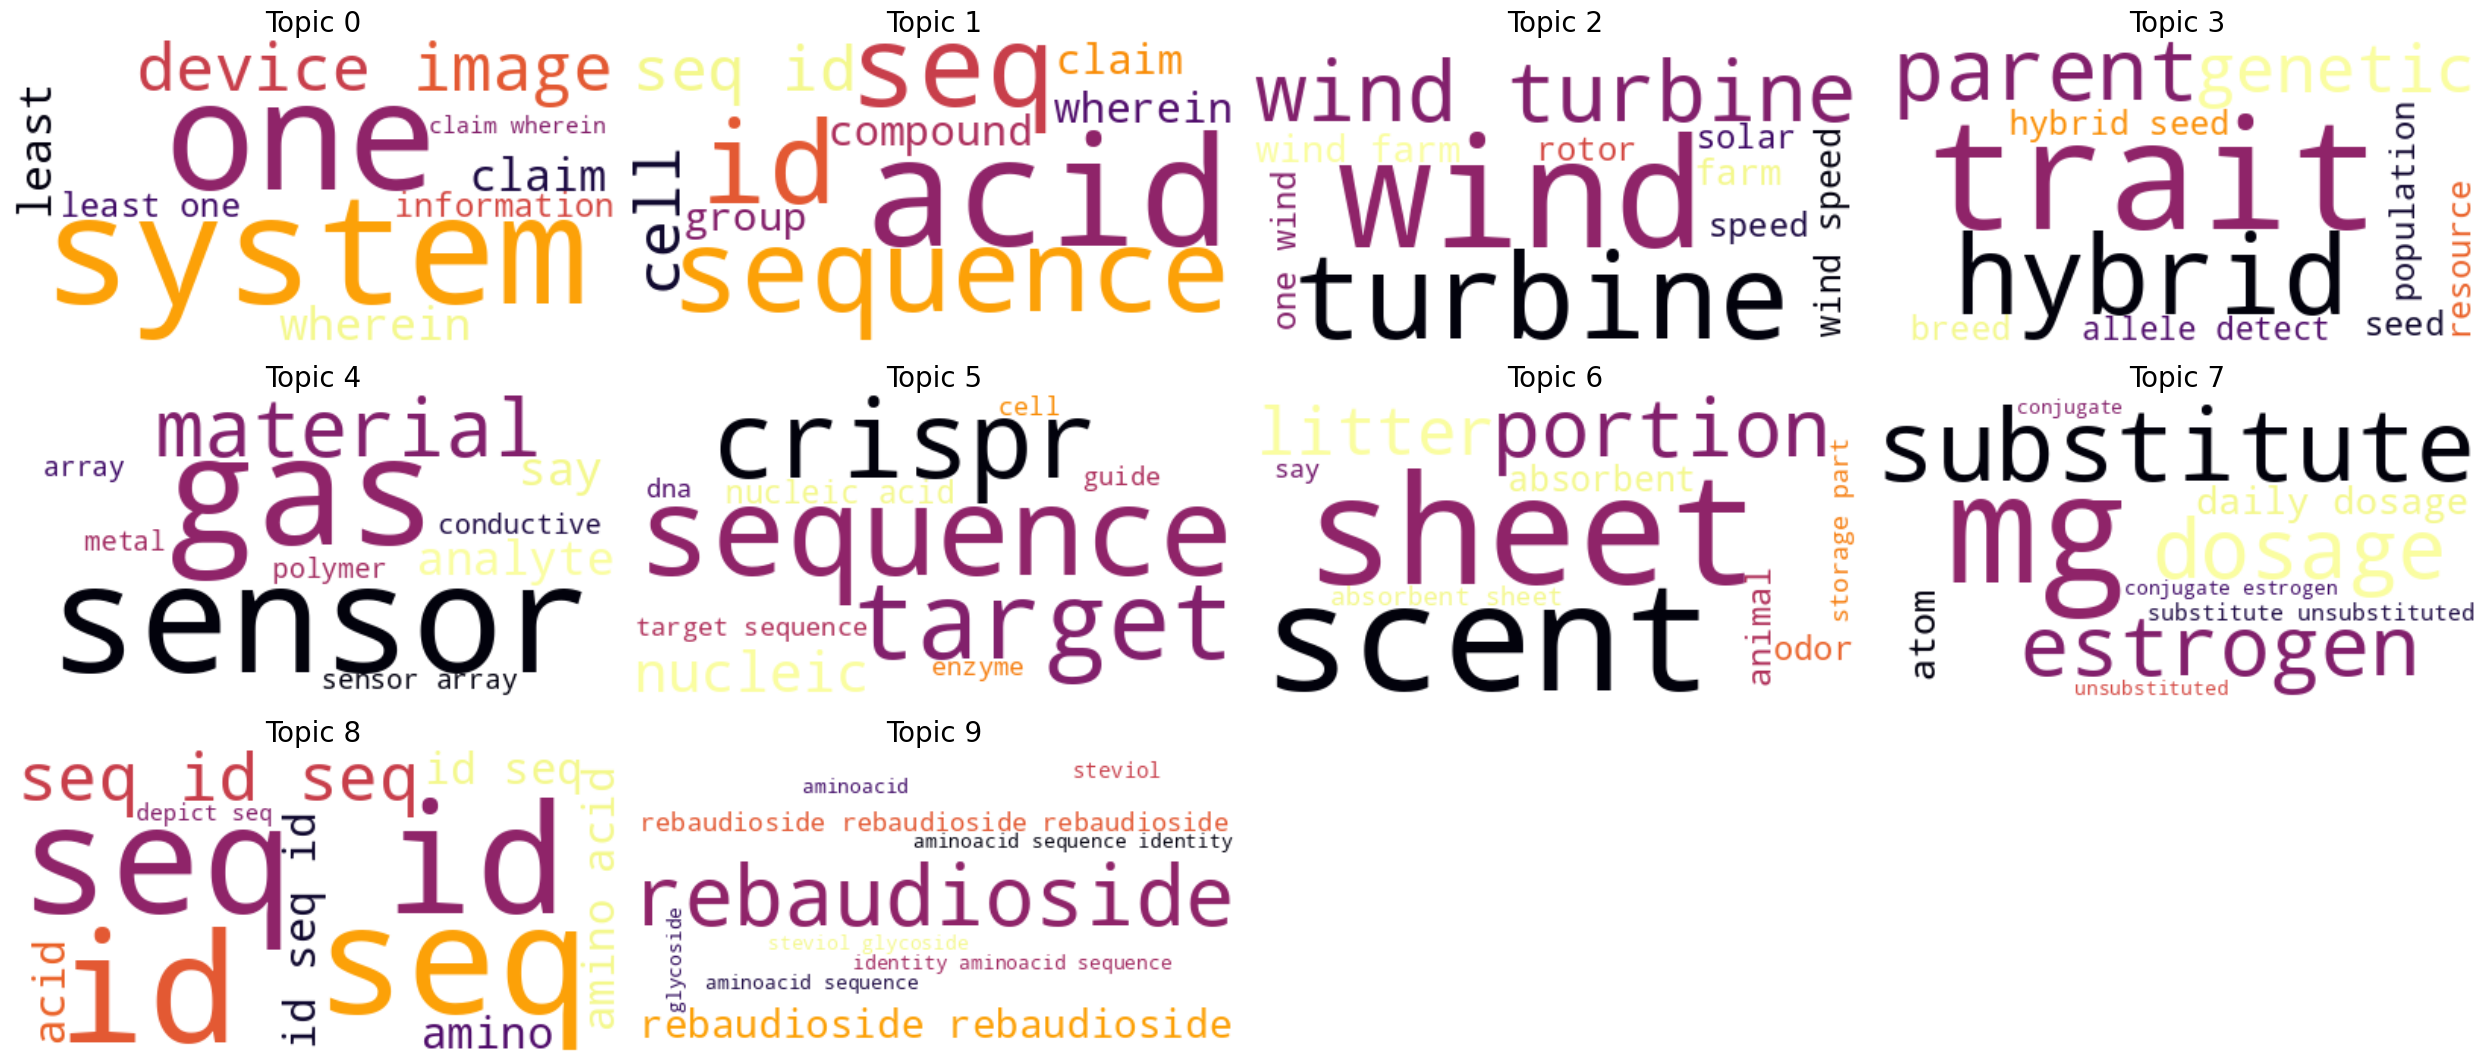

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wc_params = {
    "background_color": "white",
    "colormap": "magma_r",  # Changed colormap for better visualization
    "max_font_size": 100,
    "random_state": 30
}

plt.figure(figsize=(25, 25))

# Create a subplot for each topic
for i, (topic_id, words) in enumerate(topics.items()):
    # Generate wordcloud for each topic
    wordcloud = WordCloud(**wc_params).generate_from_frequencies(dict(words))

    # Plot each wordcloud
    plt.subplot(6,5, i+1)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.title(f"Topic {topic_id}", fontsize=20)
    plt.axis("off")

# Adjust the margin between subplots
plt.subplots_adjust(left=0.5, bottom=0.5, right=1, top=0.95, wspace=1, hspace=1)

plt.tight_layout()
plt.show()

In [ ]:
topic_model.save('Model_DTDC')

2024-06-14 10:27:54,574 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


In [ ]:
topic_model.visualize_barchart(top_n_topics=35, width=300, height=200, title='Topic Word Scores', n_words=10)

In [ ]:
model.visualize_topics_over_time(topics_over_time, topics=[9, 10, 72, 83, 87, 91])

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning:

`should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.



AttributeError: 'ARIMA' object has no attribute 'visualize_topics_over_time'

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the Excel file and parse dates
df = pd.read_excel('/content/output_with_topics_patents.xlsx', parse_dates=['Earliest publication date'])

# Extract the correct year from the 'Publication Year' column
df['year'] = df['Earliest publication date'].dt.year

# Aggregate the number of documents by year and by dominant topic
annual_data = df.groupby(['year', 'dominant_topic']).size().unstack(fill_value=0)
print(annual_data.head())

dominant_topic  0   1   2   3   4   5   6   7   8   9   ...  14  15  16  17  \
year                                                    ...                   
1995             0   0   0   0   0   0   0   0   1   0  ...   0   0   0   0   
1998             1   0   1   0   0   0   0   0   0   0  ...   0   0   0   0   
1999             1   0   0   0   0   0   0   0   0   0  ...   0   0   0   0   
2000             1   0   0   0   0   0   0   1   1   0  ...   0   0   0   0   
2001             3   0   1   0   0   0   0   0   0   0  ...   0   0   0   0   

dominant_topic  18  19  20  21  22  23  
year                                    
1995             0   0   0   0   0   0  
1998             0   0   0   0   0   0  
1999             0   0   0   0   0   0  
2000             0   0   0   0   0   0  
2001             0   0   0   0   0   0  

[5 rows x 24 columns]


In [ ]:
# Forecasting for each topic
from prophet import Prophet

forecast_horizon = 8  # Number of quarters to forecast

forecast_results = {}
for topic in time_series_data.columns:
    # Prepare the data for Prophet
    topic_data = time_series_data[[topic]].reset_index().rename(columns={'Publication Year': 'ds', topic: 'y'})

    # Ensure the column names are correct
    topic_data.columns = ['ds', 'y']

    # Check if there are at least two non-NaN rows
    if topic_data['y'].notnull().sum() >= 2:
        # Initialize and fit the model
        model = Prophet()
        model.fit(topic_data)

        # Create a dataframe to hold predictions
        future = model.make_future_dataframe(periods=forecast_horizon, freq='Q')
        forecast = model.predict(future)

        # Store the forecast
        forecast_results[topic] = forecast

        # Plot the forecast
        fig = model.plot(forecast)
        fig.suptitle(f'Topic {topic} Forecast')
        fig.show()
    else:
        print(f"Not enough data to fit the model for topic {topic}")

NameError: name 'time_series_data' is not defined

In [ ]:

from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import matplotlib.pyplot as plt

# Load the Excel file and parse dates
df = pd.read_excel('/content/output_with_topics_patents.xlsx', parse_dates=['Earliest publication date'])

# Extract the correct year from the 'Publication Year' column
df['year'] = df['Earliest publication date'].dt.year

# Aggregate the number of documents by year and by dominant topic
annual_data = df.groupby(['year', 'dominant_topic']).size().unstack(fill_value=0)
print(annual_data.head())




dominant_topic  0   1   2   3   4   5   6   7   8   9   ...  13  14  15  16  \
year                                                    ...                   
1996             0   0   0   0   0   0   0   0   0   0  ...   0   0   0   0   
1997             0   0   0   1   0   0   0   0   0   0  ...   0   0   0   0   
1998             0   0   0   0   0   1   0   0   0   0  ...   0   0   0   0   
1999             0   0   0   0   0   0   0   0   0   0  ...   0   0   0   0   
2000             1   0   0   0   0   1   0   0   0   0  ...   0   0   0   0   

dominant_topic  17  18  19  20  21  22  
year                                    
1996             0   0   0   1   0   0  
1997             0   0   0   0   0   0  
1998             0   0   0   1   1   0  
1999             1   0   0   0   0   0  
2000             0   0   0   0   0   0  

[5 rows x 23 columns]


dominant_topic  0   1   2   3   4   5   6   7   8   9   ...  14  15  16  17  \
year                                                    ...                   
1995             0   0   0   0   0   0   0   0   1   0  ...   0   0   0   0   
1998             1   0   1   0   0   0   0   0   0   0  ...   0   0   0   0   
1999             1   0   0   0   0   0   0   0   0   0  ...   0   0   0   0   
2000             1   0   0   0   0   0   0   1   1   0  ...   0   0   0   0   
2001             3   0   1   0   0   0   0   0   0   0  ...   0   0   0   0   

dominant_topic  18  19  20  21  22  23  
year                                    
1995             0   0   0   0   0   0  
1998             0   0   0   0   0   0  
1999             0   0   0   0   0   0  
2000             0   0   0   0   0   0  
2001             0   0   0   0   0   0  

[5 rows x 24 columns]


/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



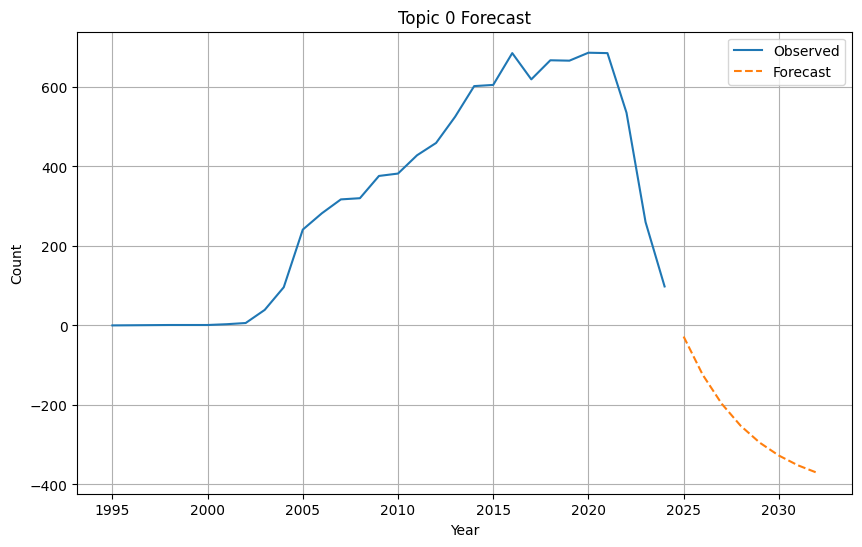

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



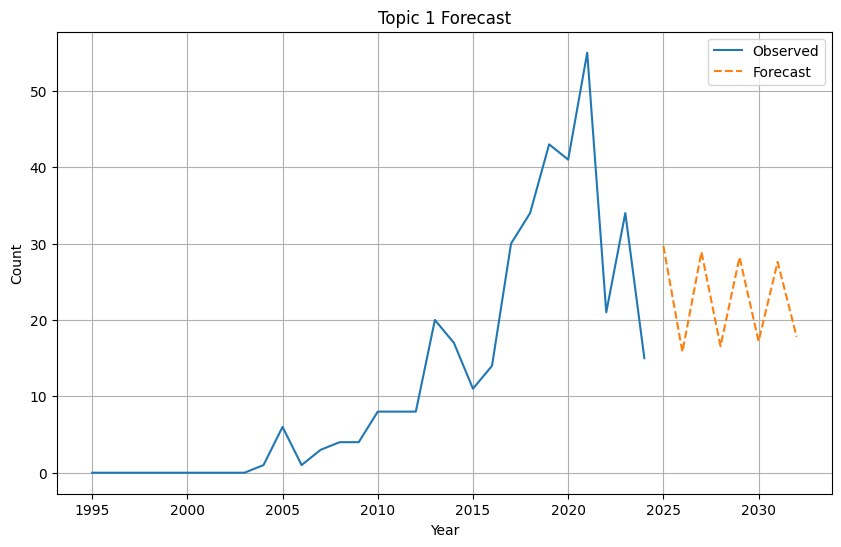

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



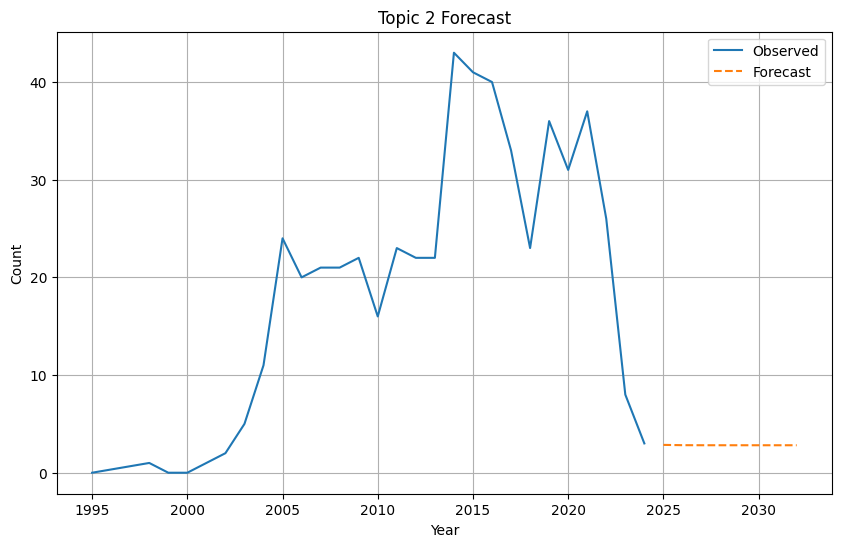

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



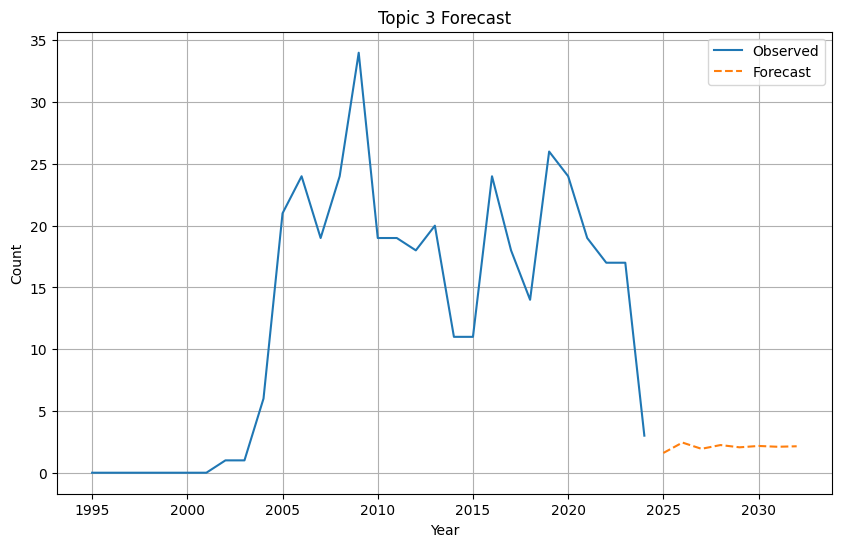

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



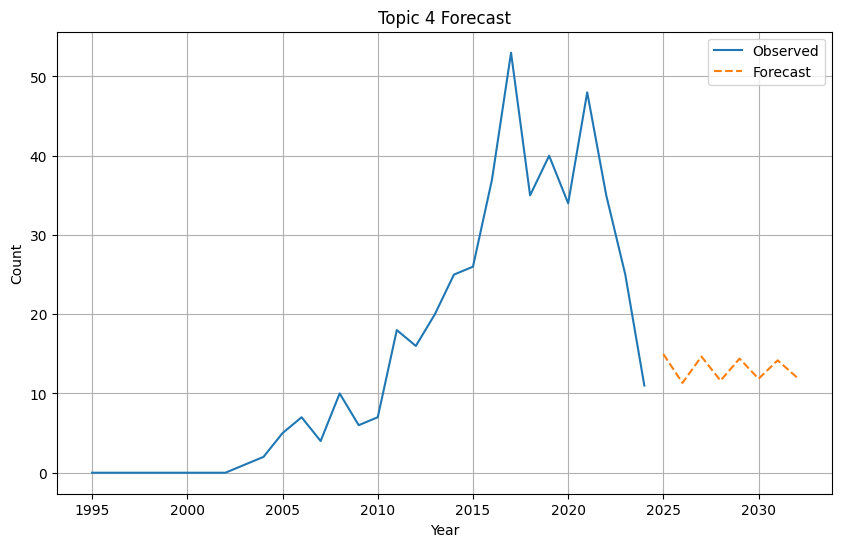

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



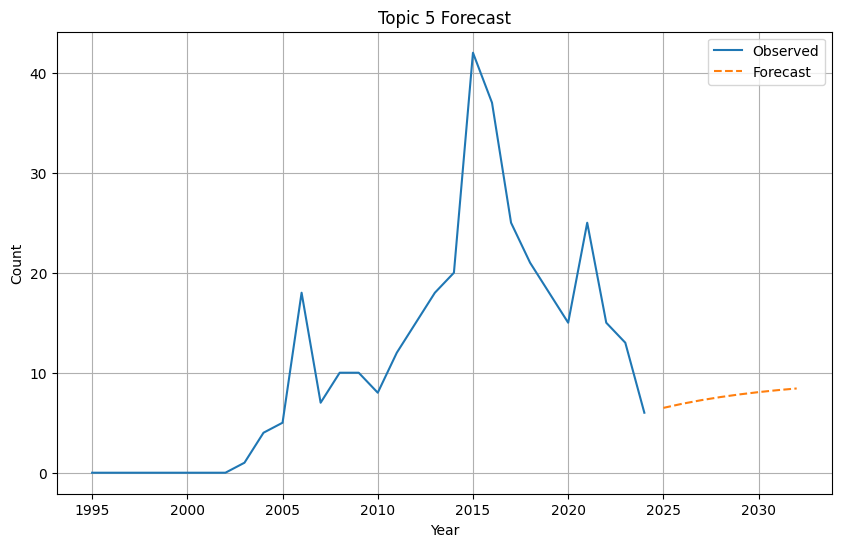

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



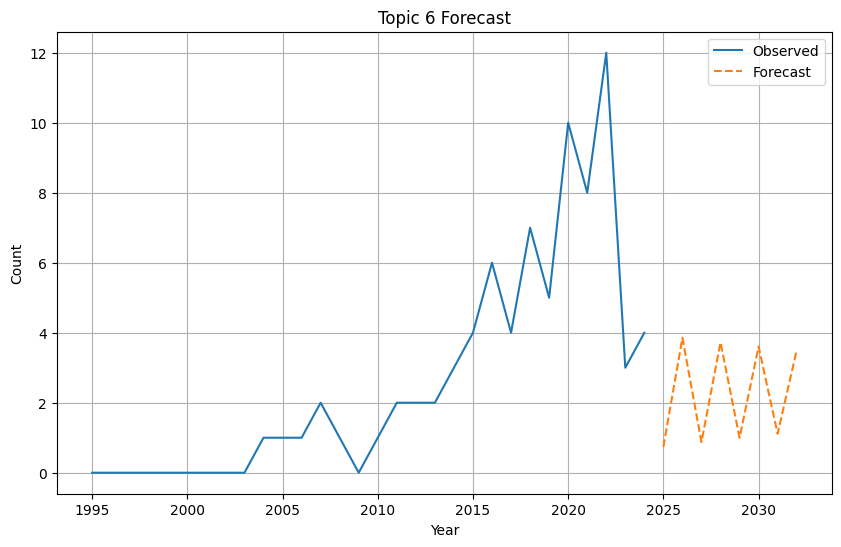

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



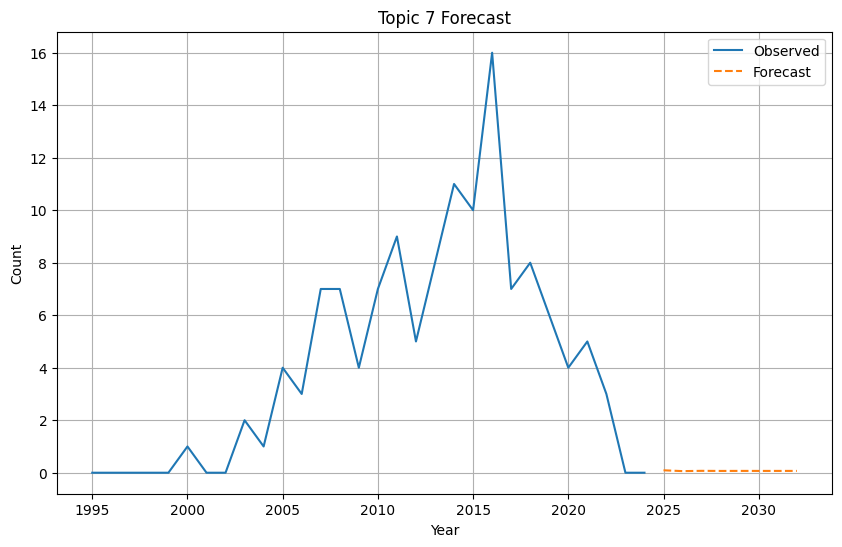

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



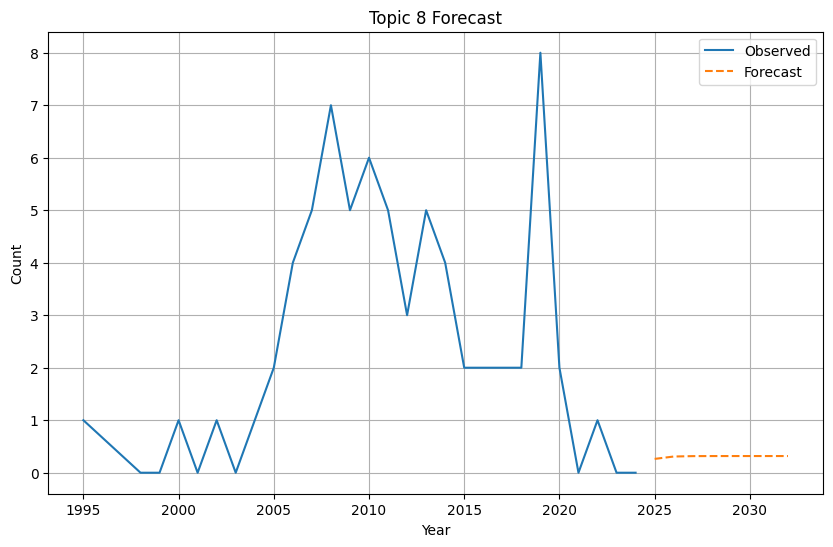

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



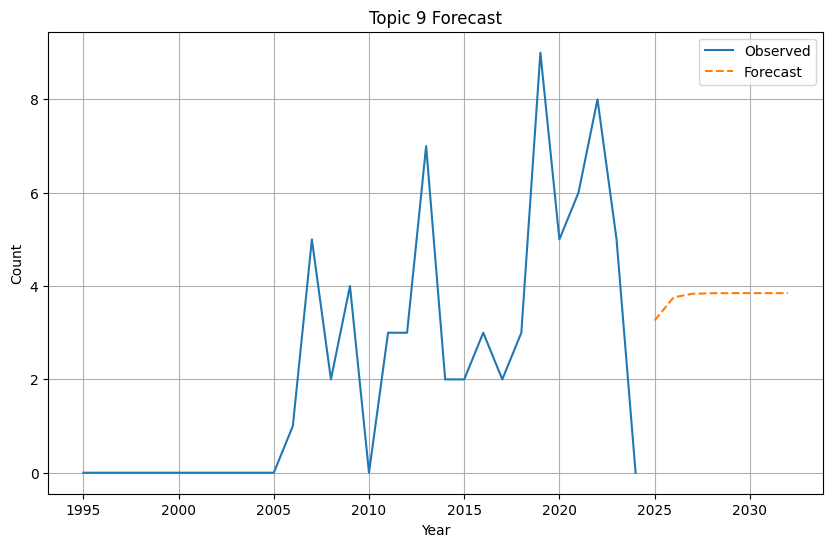

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



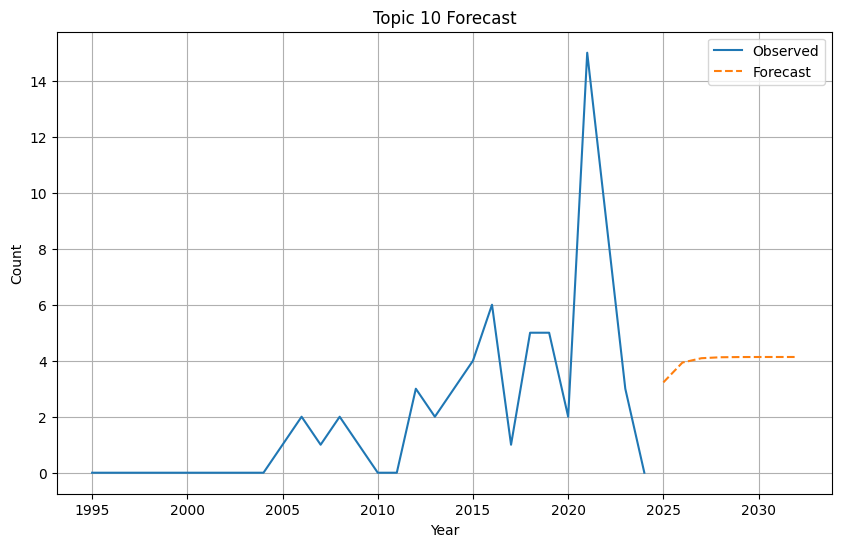

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



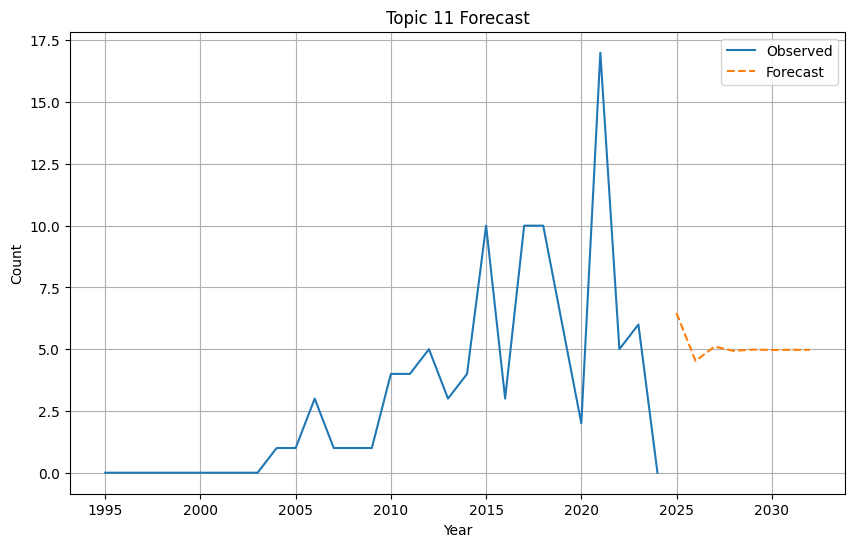

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



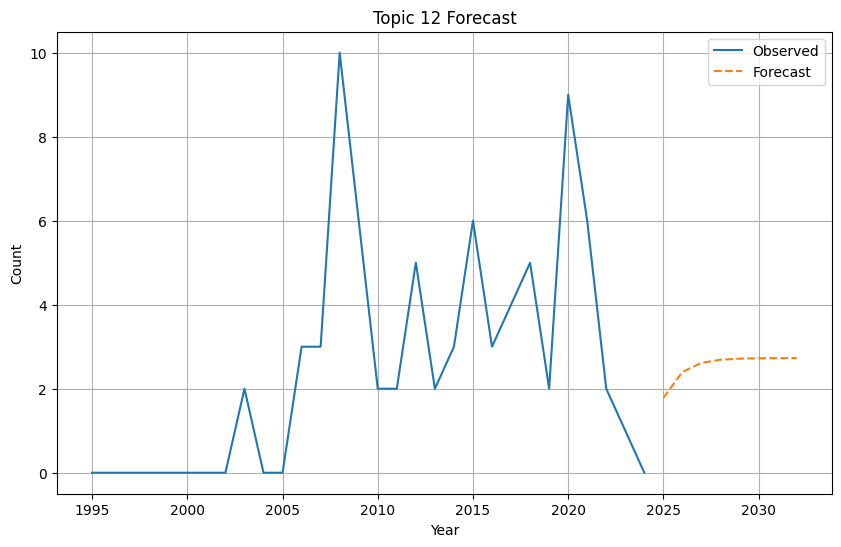

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



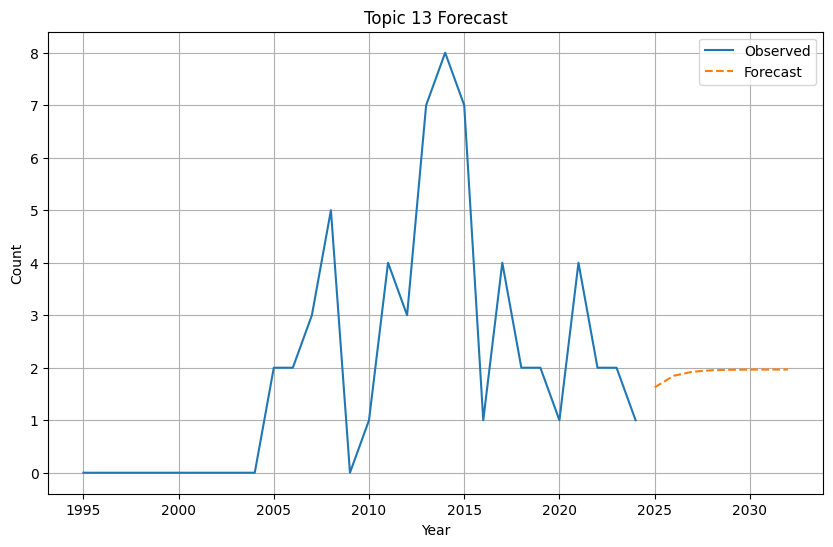

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



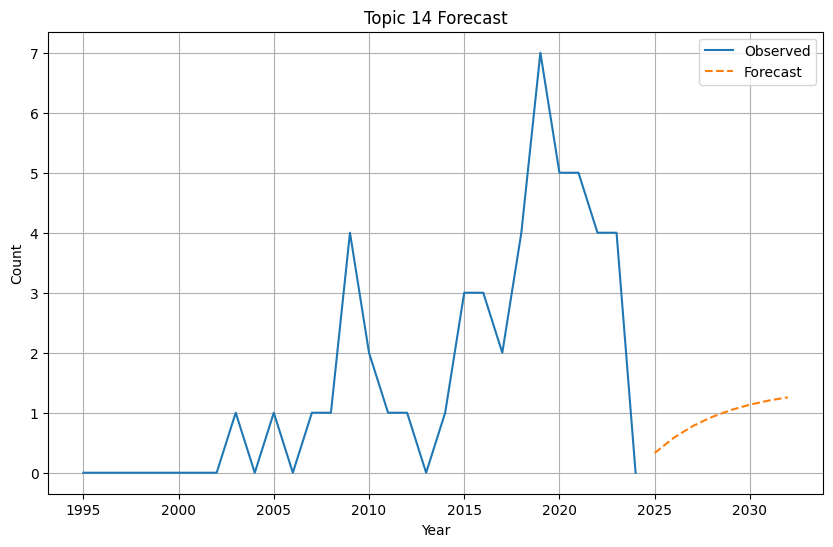

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



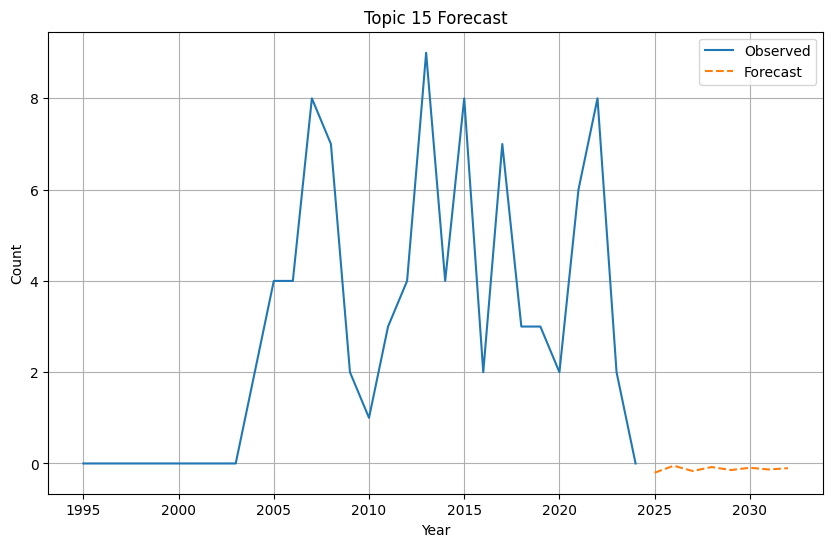

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



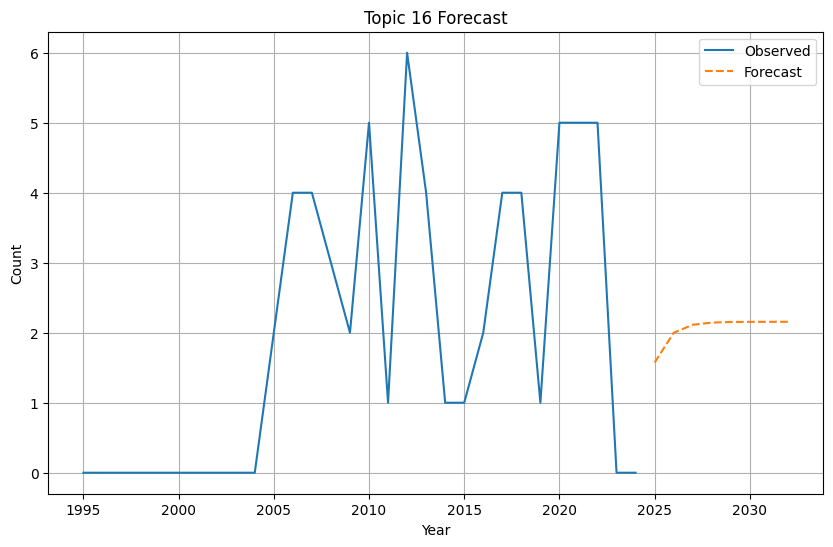

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



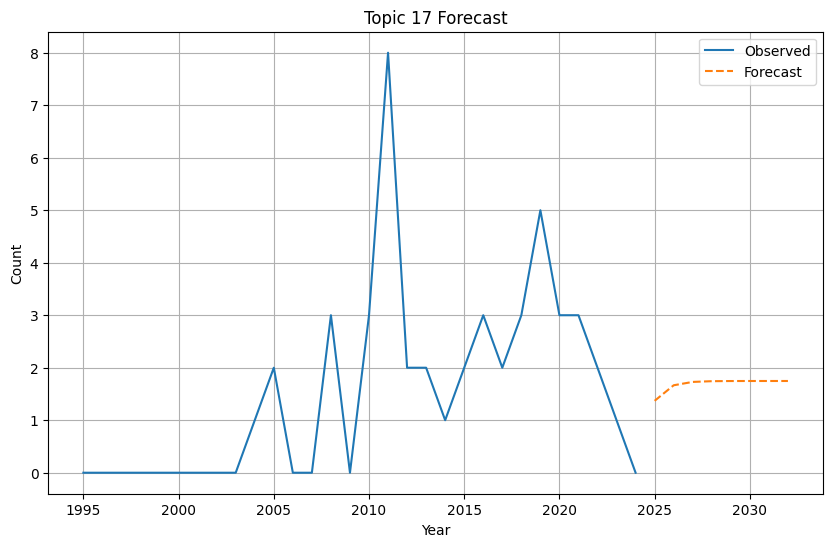

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



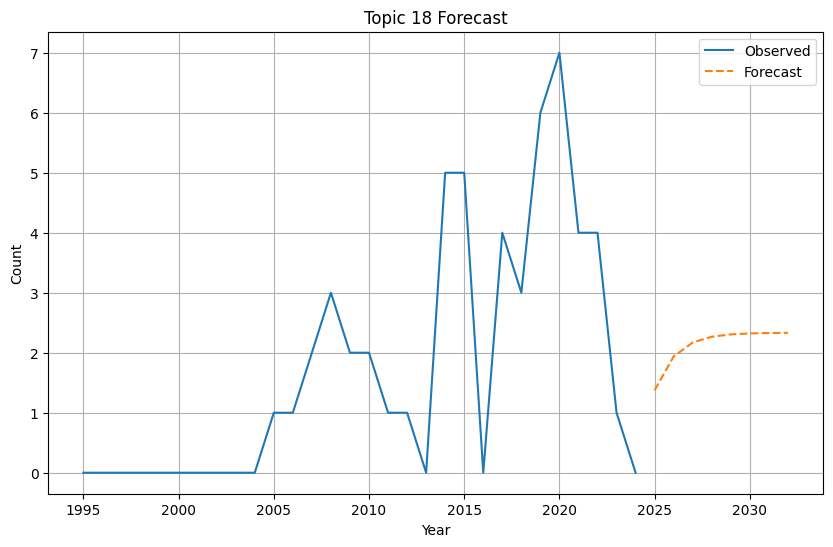

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



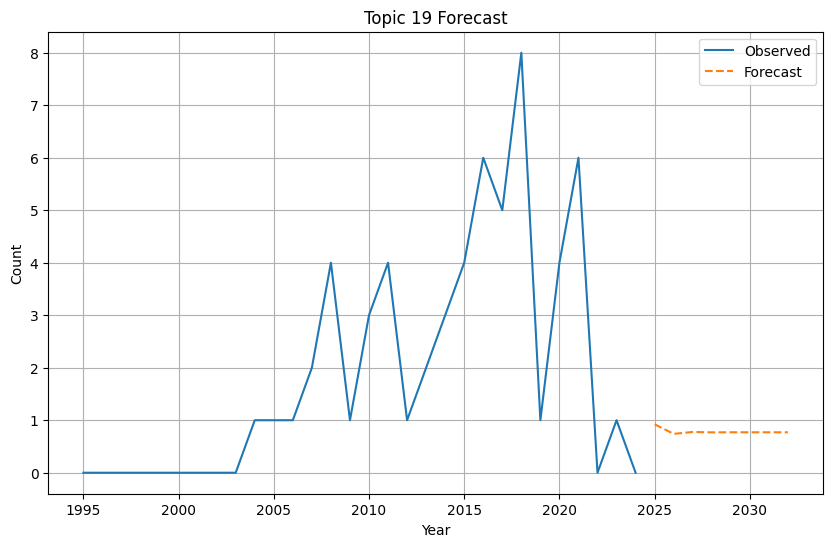

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



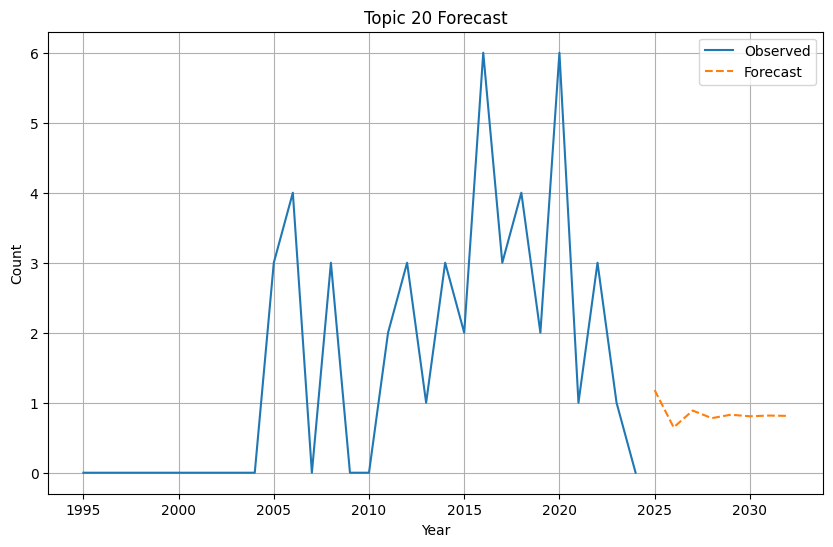

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



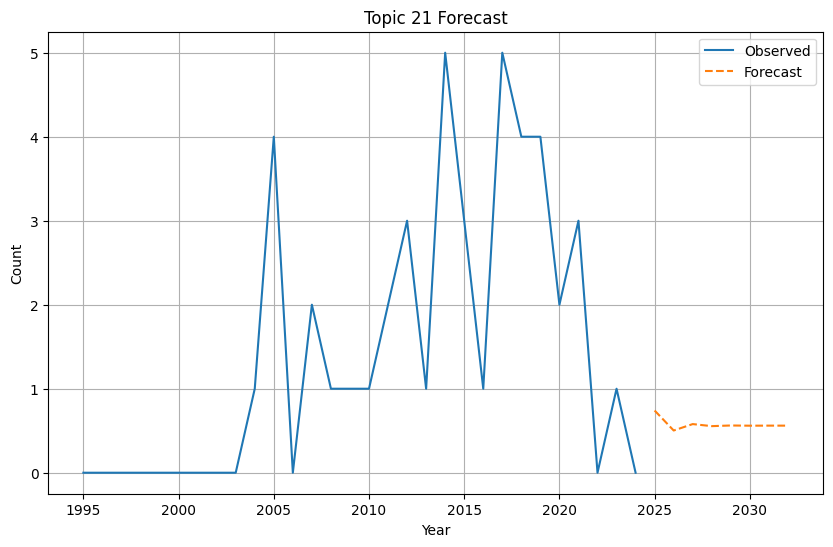

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



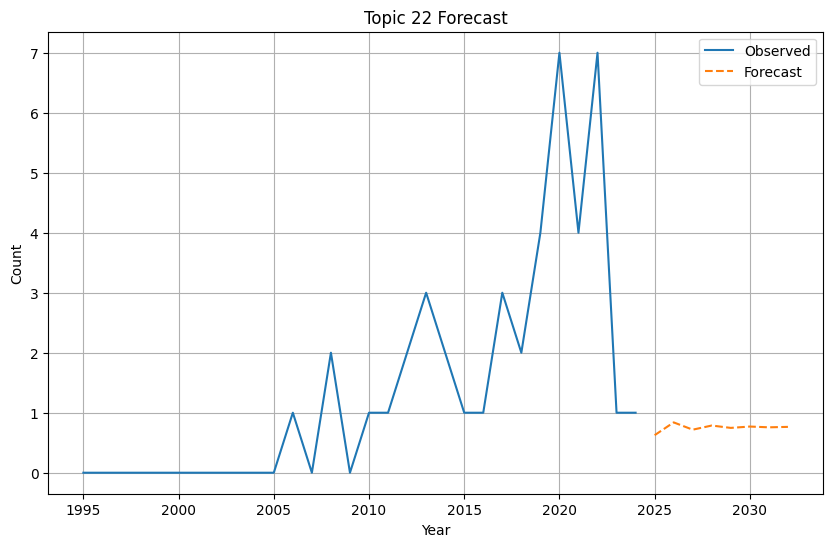

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



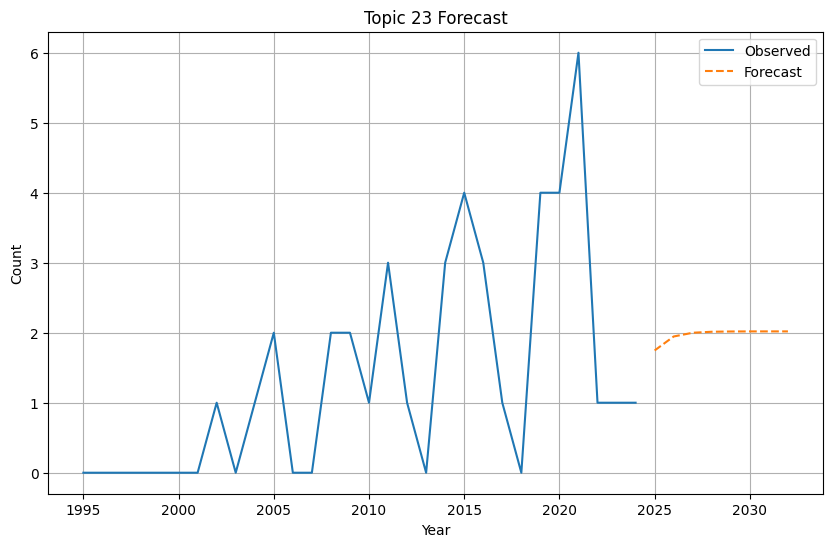

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import matplotlib.pyplot as plt

# Load the Excel file and parse dates
df = pd.read_excel('/content/output_with_topics_patents.xlsx', parse_dates=['Earliest publication date'])

# Extract the correct year from the 'Earliest publication date' column
df['year'] = df['Earliest publication date'].dt.year

# Aggregate the number of documents by year and by dominant topic
annual_data = df.groupby(['year', 'dominant_topic']).size().unstack(fill_value=0)
print(annual_data.head())

# Forecasting for each topic using ARIMA
forecast_horizon = 8  # Number of years to forecast

forecast_results = {}
for topic in annual_data.columns:
    topic_data = annual_data[[topic]].dropna()

    # Check if there are at least two non-NaN rows
    if len(topic_data) >= 2:
        # Initialize and fit the ARIMA model
        model = ARIMA(topic_data, order=(1, 1, 1))  # Example order, you may need to tune this
        model_fit = model.fit()

        # Forecast
        forecast = model_fit.forecast(steps=forecast_horizon)
        last_year = topic_data.index[-1]
        forecast_index = [last_year + i for i in range(1, forecast_horizon + 1)]
        forecast.index = forecast_index

        # Store the forecast
        forecast_results[topic] = forecast

        # Plot the forecast
        plt.figure(figsize=(10, 6))
        plt.plot(topic_data.index, topic_data, label='Observed')
        plt.plot(forecast.index, forecast, label='Forecast', linestyle='--')
        plt.title(f'Topic {topic} Forecast')
        plt.xlabel('Year')
        plt.ylabel('Count')
        plt.legend()
        plt.grid(True)
        plt.show()
    else:
        print(f"Not enough data to fit the model for topic {topic}")


dominant_topic  0   1   2   3   4   5   6   7   8   9   ...  14  15  16  17  \
year                                                    ...                   
1995             0   0   0   0   0   0   0   0   1   0  ...   0   0   0   0   
1998             1   0   1   0   0   0   0   0   0   0  ...   0   0   0   0   
1999             1   0   0   0   0   0   0   0   0   0  ...   0   0   0   0   
2000             1   0   0   0   0   0   0   1   1   0  ...   0   0   0   0   
2001             3   0   1   0   0   0   0   0   0   0  ...   0   0   0   0   

dominant_topic  18  19  20  21  22  23  
year                                    
1995             0   0   0   0   0   0  
1998             0   0   0   0   0   0  
1999             0   0   0   0   0   0  
2000             0   0   0   0   0   0  
2001             0   0   0   0   0   0  

[5 rows x 24 columns]


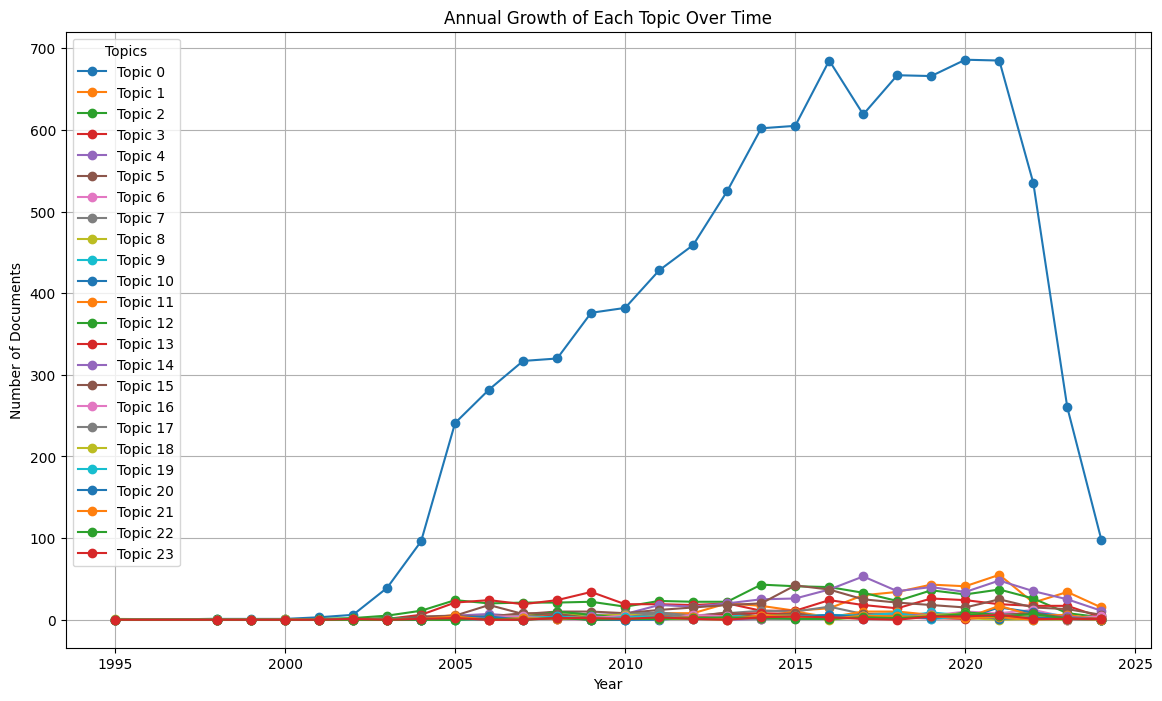

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the Excel file and parse dates
df = pd.read_excel('/content/output_with_topics_patents.xlsx', parse_dates=['Earliest publication date'])

# Extract the correct year from the 'Publication Year' column
df['year'] = df['Earliest publication date'].dt.year

# Aggregate the number of documents by year and by dominant topic
annual_data = df.groupby(['year', 'dominant_topic']).size().unstack(fill_value=0)
print(annual_data.head())

# Plotting the annual growth of each topic
plt.figure(figsize=(14, 8))
for topic in annual_data.columns:
    plt.plot(annual_data.index, annual_data[topic], marker='o', label=f'Topic {topic}')
plt.title('Annual Growth of Each Topic Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Documents')
plt.legend(title='Topics')
plt.grid(True)
plt.show()


In [ ]:
import pyLDAvis
import pyLDAvis.gensim_models
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.vectorizers import ClassTfidfTransformer

# Fit BERTopic model to input data
topics, probs = topic_model.fit_transform(df['cleaned_text'], embeddings=embeddings)

# Reduce outliers
new_topics = topic_model.reduce_outliers(df['cleaned_text'], topics)

# Update topics
topic_model.update_topics(
    df['cleaned_text'],
    topics=new_topics,
    vectorizer_model=None,  # Assuming no specific vectorizer model passed initially
    representation_model=MaximalMarginalRelevance(diversity=0.8),
    ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True)
)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning:

`should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.

2024-05-19 14:44:57,214 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


SystemError: CPUDispatcher(<function nn_descent at 0x7e2ea6ad79a0>) returned a result with an exception set

In [ ]:
# Prepare data for PyLDAvis
def prepare_pyladvis_data(topic_model, df, probs):
    vectorizer = CountVectorizer()
    doc_term_matrix = vectorizer.fit_transform(df['cleaned_text'])

    # Get topic-term distributions and term frequencies
    topics = topic_model.get_topics()

    # Create a mapping from topic ID to index
    topic_id_to_index = {topic_id: idx for idx, topic_id in enumerate(topics.keys()) if topic_id != -1}

    # Initialize term-topic matrix
    num_topics = len(topic_id_to_index)
    num_terms = len(vectorizer.get_feature_names_out())
    topic_term_matrix = np.zeros((num_topics, num_terms))

    # Fill the term-topic matrix
    for topic_id, terms in topics.items():
        if topic_id == -1:  # Skip outliers
            continue
        row_index = topic_id_to_index[topic_id]
        for word, weight in terms:
            if word in vectorizer.vocabulary_:
                term_index = vectorizer.vocabulary_[word]
                topic_term_matrix[row_index, term_index] = weight

    # Normalize the topic-term matrix
    topic_term_dists = topic_term_matrix / topic_term_matrix.sum(axis=1, keepdims=True)

    # Ensure doc_topic_dists rows sum to 1
    doc_topic_dists = probs / probs.sum(axis=1, keepdims=True)
    doc_lengths = [len(doc.split()) for doc in df['cleaned_text']]
    vocab = vectorizer.get_feature_names_out()
    term_frequency = doc_term_matrix.sum(axis=0).A1

    return {
        'topic_term_dists': topic_term_dists,
        'doc_topic_dists': doc_topic_dists,
        'doc_lengths': doc_lengths,
        'vocab': vocab,
        'term_frequency': term_frequency
    }

data = prepare_pyladvis_data(topic_model, df, probs)

# Create the PyLDAvis visualization
vis_data = pyLDAvis.prepare(
    topic_term_dists=data['topic_term_dists'],
    doc_topic_dists=data['doc_topic_dists'],
    doc_lengths=data['doc_lengths'],
    vocab=data['vocab'],
    term_frequency=data['term_frequency']
)

pyLDAvis.display(vis_data)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning:

`should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.

/usr/local/lib/python3.10/dist-packages/pandas/core/internals/blocks.py:329: RuntimeWarning:

divide by zero encountered in log

/usr/local/lib/python3.10/dist-packages/pandas/core/internals/blocks.py:329: RuntimeWarning:

divide by zero encountered in log

/usr/local/lib/python3.10/dist-packages/pandas/core/internals/blocks.py:329: RuntimeWarning:

divide by zero encountered in log

/usr/local/lib/python3.10/dist-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning:

os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.



In [ ]:
!pip install pyLDAvis

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 9.7 MB/s eta 0:00:00
